In [1]:
from __future__ import print_function
import os
try:
    from urllib.request import urlretrieve
except ImportError:
    from urllib import urlretrieve

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
import string
import warnings

# for all NLP related operations on text
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.stem import WordNetLemmatizer
from nltk.stem.porter import *
from nltk.classify import NaiveBayesClassifier
#from wordcloud import WordCloud

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn import preprocessing

import datetime as dt


# ignoring all the warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# downloading stopwords corpus
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')
nltk.download('movie_reviews')
nltk.download('punkt')
nltk.download('conll2000')
nltk.download('brown')
stopwords = set(stopwords.words("english"))

# for showing all the plots inline
%matplotlib inline


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Raj\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Raj\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Raj\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\Raj\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\Raj\AppData\Roaming\nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Raj\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-d

In [4]:
all_ticket_df=pd.read_csv('all_ticketsnew.csv')

In [5]:
# all_ticket_df['body'] = (all_ticket_df['title'] +   " " + all_ticket_df['body']).map(str)

In [7]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')

def plot_history(history):
        
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training Accuracy')
    plt.plot(x, val_acc, 'r', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Model Loss')
    plt.legend()
    

In [8]:
all_ticket_df = datacleansing(all_ticket_df,getRegexList())

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Raj\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [9]:
all_ticket_df.head()

,title,body,ticket_type,category,sub_category1,sub_category2,business_service,urgency,impact,body-tokenized
1,connection with icon,connection with icon icon dear please setup ic...,1,6,22,7,26,3,4,"[c, n, n, e, c, n, , w, h, , c, n, , c, n, ..."
2,work experience user,work experience user work experience user work...,1,5,13,7,32,3,4,"[w, r, k, , e, x, p, e, r, e, n, c, e, , u, ..."
3,requesting for meeting,requesting for meeting requesting meeting plea...,1,5,13,7,32,3,4,"[r, e, q, u, e, n, g, , f, r, , e, e, n, g, ..."
4,reset passwords for external accounts,reset passwords for external accounts expire d...,1,4,2,76,4,3,4,"[r, e, e, , p, w, r, , f, r, , e, x, e, r, ..."
5,mail,mail verification warning has got attached ple...,1,4,3,7,89,3,4,"[l, , v, e, r, f, c, n, , w, r, n, n, g, , ..."


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Use 'category' as target since this is a multi-class notebook
label_encoder = LabelEncoder()
labelData = label_encoder.fit_transform(all_ticket_df['category'].astype(str))
num_classes = len(label_encoder.classes_)
print('Number of classes:', num_classes)

data = all_ticket_df['body'].astype(str)

# Split dataset into training and testing data (stratified for balanced classes)
train_data, test_data, train_labels, test_labels = train_test_split(
        data, labelData, test_size=0.2, random_state=42, stratify=labelData
    )

In [11]:
from numpy import array
from keras.preprocessing.text import one_hot
from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers.embeddings import Embedding

Using TensorFlow backend.


In [12]:
# load the whole embedding into memory
from keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer(num_words=100000)
tokenizer.fit_on_texts(train_data)
X_train = tokenizer.texts_to_sequences(train_data)
X_test = tokenizer.texts_to_sequences(test_data)
vocab_length = len(tokenizer.word_index) + 1

In [13]:
corpus = all_ticket_df['body'].to_list()
word_count = lambda sentence: len(word_tokenize(sentence))
longest_sentence = max(corpus, key=word_count)
length_long_sentence = len(word_tokenize(longest_sentence))

print(length_long_sentence)

911


In [14]:
from keras.utils import to_categorical
from keras.preprocessing import sequence
#print(len(x_train))
#print(len(X_test))
#print(np.shape(x_train))
#print(np.shape(X_test))

X_train = pad_sequences(X_train, length_long_sentence, padding='post')
X_test = pad_sequences(X_test, length_long_sentence, padding='post')


In [ ]:
# define model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, LSTM, GRU, Dropout, SpatialDropout1D
from tensorflow.keras.optimizers import Adam

embedding_dim = 100

model = Sequential()
model.add(Embedding(vocab_length, embedding_dim, input_length=length_long_sentence))
model.add(SpatialDropout1D(0.2))
model.add(GRU(units=64, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(num_classes, activation='softmax'))

model.compile(optimizer=Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

In [ ]:
# fit the model
from tensorflow.keras.callbacks import EarlyStopping

y_train = train_labels
y_test = test_labels

print(len(X_test))
print(len(y_test))

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    epochs=10,
                    verbose=True,
                    batch_size=64,
                    validation_data=(X_test, y_test),
                    callbacks=[early_stop])

Training Accuracy: 0.7107
Testing Accuracy:  0.7144
dict_keys(['val_loss', 'val_accuracy', 'loss', 'accuracy'])


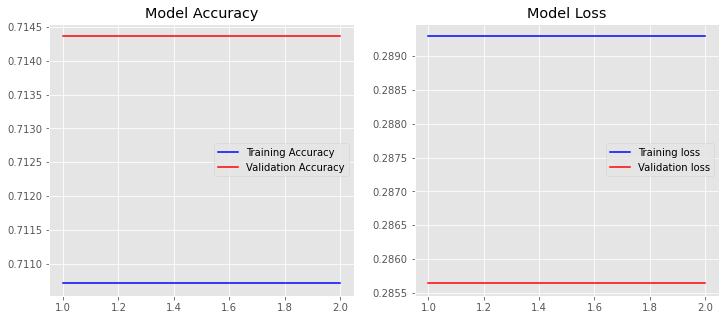

In [39]:
# evaluate the model
#loss, accuracy = model.evaluate(padded_sentences, all_ticket_df['ticket_type'], verbose=0)
#print('Accuracy: %f' % (accuracy*100))

loss, accuracy = model.evaluate(X_train, y_train, verbose=False)
print("Training Accuracy: {:.4f}".format(accuracy))

loss, accuracy = model.evaluate(X_test, y_test, verbose=False)
print("Testing Accuracy:  {:.4f}".format(accuracy))

print(history.history.keys())
plot_history(history)

In [ ]:
#Predict
import numpy as np

textd_1 = "hello movement has left available device please kind device denmark copenhagen denmark please source quotation shipping by lead"
textd_2 = "cannot submit hours getting error job defined for person assignment human resources application error"

testd = [textd_1, textd_2]
testd_tokens = tokenizer.texts_to_sequences(testd)
testd_tokens_pad = pad_sequences(testd_tokens, length_long_sentence, padding='post')

probs = model.predict(x=testd_tokens_pad)
predicted_classes = label_encoder.inverse_transform(np.argmax(probs, axis=1))
print('Predicted categories:', predicted_classes)